In [1]:
# parameters
DEVICE = 'cpu'
SEED   = 42     # change to 123 or 777 for other runs

import numpy as np
import torch
import torch.distributions as TD
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from tqdm import tqdm
from IPython.display import clear_output
import random, os, sys
sns.set_theme(style="ticks", palette="pastel")

from OFM.ofmsrc.icnn import ICNN2CPF
from OFM.ofmsrc.model_tools import (
    id_pretrain_model, ofm_loss,
    TorchlbfgsInvParams, BruteforceIHVParams,
)
from OFM.ofmsrc.dgm_utils import visualize_2d_samples_groups, visualize_2d_map
from OFM.ofmsrc.tools import EMA
from OFM.ofmsrc.distributions import Sampler, StandardNormalSampler

In [2]:
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.random.manual_seed(seed)
    random.seed(seed)

## Gaussian Mixture Sampler

In [3]:
class GaussianMixture(Sampler):
    """
    parameters: list of dicts with keys:
        "mean" : list of length dim
        "std"  : list of length dim  (diagonal covariance)
    All components equally weighted.
    """
    def __init__(self, parameters, device='cpu'):
        super().__init__(device=device)
        self.dim   = len(parameters[0]["mean"])
        self.means = torch.tensor(
            [p["mean"] for p in parameters], dtype=torch.float32, device=device)
        self.stds  = torch.tensor(
            [p["std"]  for p in parameters], dtype=torch.float32, device=device)
        self.K = len(parameters)
        # also keep numpy version for KDE plotting
        self.means_np = self.means.cpu().numpy()
        self.stds_np  = self.stds.cpu().numpy()

    def sample(self, batch_size=10):
        idx   = torch.randint(0, self.K, (batch_size,), device=self.device)
        means = self.means[idx]
        stds  = self.stds[idx]
        return means + stds * torch.randn(batch_size, self.dim, device=self.device)

    def sample_np(self, n):
        """Returns numpy array of shape (n, dim)."""
        return self.sample(n).cpu().numpy()

## Distributions

In [4]:
# ── Distributions ─────────────────────────────────────────────────────────────

seed_everything(SEED)

_r = 3.0
_s = _r / np.sqrt(2)
parameters = [
    {"mean": [ _r,   0], "std": [0.4, 0.4]},
    {"mean": [-_r,   0], "std": [0.4, 0.4]},
    {"mean": [  0,  _r], "std": [0.4, 0.4]},
    {"mean": [  0, -_r], "std": [0.4, 0.4]},
    {"mean": [ _s,  _s], "std": [0.4, 0.4]},
    {"mean": [ _s, -_s], "std": [0.4, 0.4]},
    {"mean": [-_s,  _s], "std": [0.4, 0.4]},
    {"mean": [-_s, -_s], "std": [0.4, 0.4]},
]
mixture        = GaussianMixture(parameters, device=DEVICE)
source_sampler = StandardNormalSampler(device=DEVICE)
target_sampler = mixture

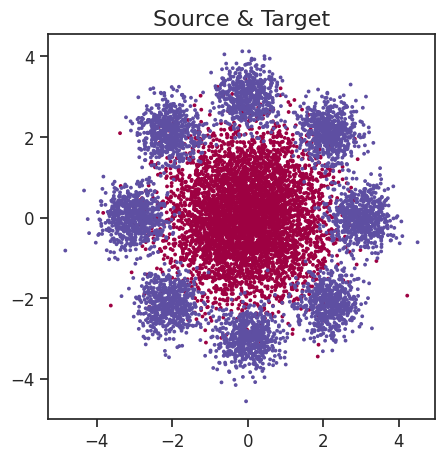

In [5]:
visualize_2d_samples_groups([
    source_sampler.sample(5024).cpu().numpy(),
    target_sampler.sample(5024).cpu().numpy()
], 'Source & Target', s=3)

## Model

In [6]:
# ── Model & Optimizer ─────────────────────────────────────────────────────────

seed_everything(SEED)

_prior = TD.Normal(
    torch.tensor([0., 0.]).to(DEVICE),
    torch.tensor([4., 4.]).to(DEVICE))

model = ICNN2CPF(dim=2, dimh=1024, num_hidden_layers=2, batch_size=1024).to(DEVICE)
id_pretrain_model(model, _prior, n_max_iterations=200, lr=1e-2)
optim = torch.optim.Adam(model.parameters(), lr=1e-2)

100%|██████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:30<00:00,  6.55it/s]

Loss: 0.37094375491142273


## Output directory

In [7]:
# ── Output directory ──────────────────────────────────────────────────────────
EXP_DIR = './gaumix_ofm'
os.makedirs(EXP_DIR, exist_ok=True)

samples_path    = os.path.join(EXP_DIR, 'samples.png')
curr_model_path = os.path.join(EXP_DIR, 'model.pth')
loss_path       = os.path.join(EXP_DIR, 'loss.png')

## Training

Iteration 4500  |  Loss: 21.0248


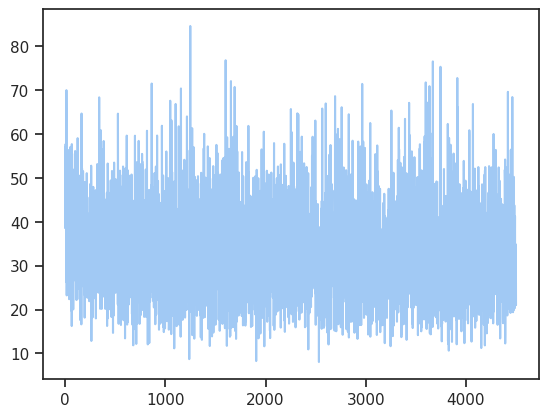

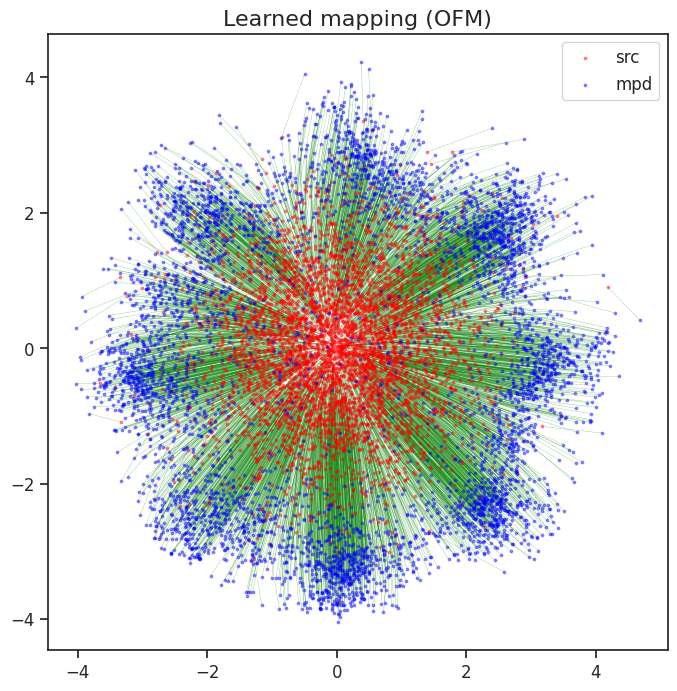

100%|██████████████████████████████████████████████████████████████████████| 5000/5000 [09:28<00:00,  8.80it/s, loss=0.941, tloss=27]


In [8]:
MAX_ITER      = 5000
BATCH_SIZE    = 16
INV_TOLERANCE = 0.01

_np_state, _torch_state = np.random.get_state(), torch.get_rng_state()
ema = EMA(0, betas=[0.999, 0.99])
np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

loss_history = []

print('Fitting the Gaussian Mixture with OFM')
with tqdm(range(MAX_ITER)) as tbar:
    for iteration in tbar:
        X = source_sampler.sample(BATCH_SIZE).to(DEVICE)
        Y = target_sampler.sample(BATCH_SIZE).to(DEVICE)
        t = (torch.rand(BATCH_SIZE) + 1e-8).to(DEVICE)

        metrics = {}
        loss, true_loss = ofm_loss(
            model, X, Y, t,
            TorchlbfgsInvParams(lbfgs_params=dict(tolerance_grad=INV_TOLERANCE), max_iter=5),
            BruteforceIHVParams(), stats=metrics,
        )
        optim.zero_grad(); loss.backward()
        optim.step(); model.convexify()

        _np_state, _torch_state = np.random.get_state(), torch.get_rng_state()
        ema(model)
        np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

        loss_history.append(true_loss.item())
        tbar.set_postfix(loss=loss.item(), tloss=true_loss.item())

        if iteration % 500 == 0:
            _np_state, _torch_state = np.random.get_state(), torch.get_rng_state()

            clear_output(wait=True)
            print(f"Iteration {iteration}  |  Loss: {true_loss.item():.4f}")
            plt.plot(loss_history); plt.savefig(loss_path); plt.show()

            X_vis = source_sampler.sample(5000).to(DEVICE)
            Y_vis = model.push_nograd(X_vis)
            visualize_2d_map(
                X_vis.cpu().numpy(), Y_vis.cpu().numpy(), 'Learned mapping (OFM)',
                data_label='src', mapped_data_label='mpd',
                s=3, figsize=(8, 8), save_path=samples_path)

            torch.save(model.state_dict(), curr_model_path)
            for beta in [0.999, 0.99]:
                torch.save(ema.get_model(beta),
                           os.path.join(EXP_DIR, f'model_{beta}.pth'))

            np.random.set_state(_np_state); torch.set_rng_state(_torch_state)

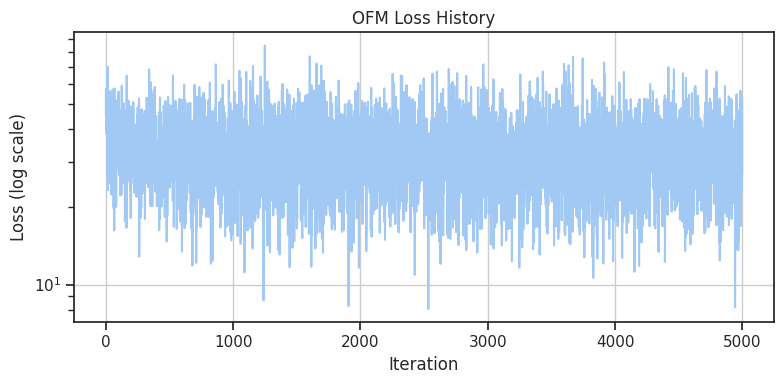

In [9]:
# ── Loss History ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss_history)
ax.set_yscale('log')
ax.set_xlabel('Iteration')
ax.set_ylabel('Loss (log scale)')
ax.set_title('OFM Loss History')
ax.grid(True)
plt.tight_layout()
plt.show()

═══════════════════════════════════════════════════════════════════════════════
POST-TRAINING ANALYSIS
═══════════════════════════════════════════════════════════════════════════════

[OFM]  Fréchet Distance (2D): 0.090002
[OFM]  Wasserstein-2        : 0.495862


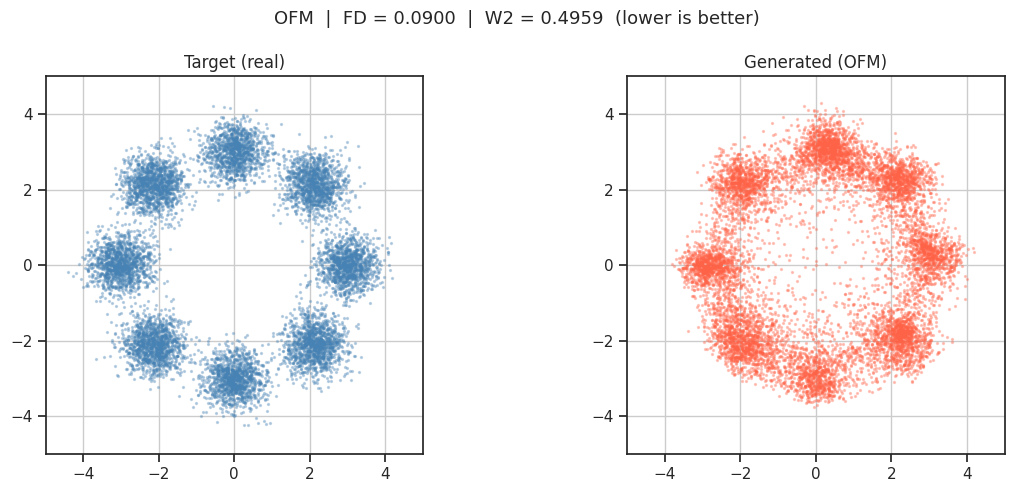

Saved generated and real samples → ./gaumix_ofm/


In [10]:
# ── Fréchet Distance + Wasserstein-2 + Save samples ──────────────────────────
from scipy.linalg import sqrtm
import ot

def frechet_distance(real_samples, gen_samples):
    mu_r = real_samples.mean(axis=0)
    mu_g = gen_samples.mean(axis=0)
    sigma_r = np.cov(real_samples, rowvar=False)
    sigma_g = np.cov(gen_samples, rowvar=False)
    diff = mu_r - mu_g
    covmean = sqrtm(sigma_r @ sigma_g)
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff @ diff + np.trace(sigma_r + sigma_g - 2 * covmean))

def wasserstein2(real_samples, gen_samples, n_sub=2000, seed=0):
    rng = np.random.RandomState(seed)
    idx_r = rng.choice(len(real_samples), size=min(n_sub, len(real_samples)), replace=False)
    idx_g = rng.choice(len(gen_samples),  size=min(n_sub, len(gen_samples)),  replace=False)
    r, g = real_samples[idx_r], gen_samples[idx_g]
    n, m = len(r), len(g)
    M = ot.dist(r, g, metric='sqeuclidean')
    w2_sq = ot.emd2(np.ones(n) / n, np.ones(m) / m, M)
    return float(np.sqrt(w2_sq))

N_FD = 10_000

# Reset RNG to training seed before evaluation so results match run_comparison.py
seed_everything(SEED)

model.eval()
x_src_np = source_sampler.sample(N_FD).cpu().numpy()
x_src_t  = torch.tensor(x_src_np, dtype=torch.float32, requires_grad=True).to(DEVICE)
x_gen    = model.push_nograd(x_src_t).detach().cpu().numpy()

x_real = target_sampler.sample_np(N_FD)

fd = frechet_distance(x_real, x_gen)
w2 = wasserstein2(x_real, x_gen)
print(f"[OFM]  Fréchet Distance (2D): {fd:.6f}")
print(f"[OFM]  Wasserstein-2        : {w2:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f'OFM  |  FD = {fd:.4f}  |  W2 = {w2:.4f}  (lower is better)', fontsize=13)

for ax, pts, label, color in zip(
    axes,
    [x_real, x_gen],
    ['Target (real)', 'Generated (OFM)'],
    ['steelblue', 'tomato'],
):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.3, color=color)
    ax.set_title(label)
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    ax.set_aspect('equal'); ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, 'fd_comparison.png'), dpi=120)
plt.show()

np.save(os.path.join(EXP_DIR, 'generated_samples.npy'), x_gen)
np.save(os.path.join(EXP_DIR, 'real_samples.npy'),      x_real)
print(f"Saved generated and real samples → {EXP_DIR}/")